In [1]:
pip install stim pymatching numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 23.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 625.9/625.9 kB 17.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pymatching]


d=3 p=0.0020  logical error rate = 0.00303 +/- 0.00017
d=3 p=0.0033  logical error rate = 0.00797 +/- 0.00028
d=3 p=0.0045  logical error rate = 0.01345 +/- 0.00036
d=3 p=0.0057  logical error rate = 0.02199 +/- 0.00046
d=3 p=0.0070  logical error rate = 0.03237 +/- 0.00056
d=3 p=0.0083  logical error rate = 0.04154 +/- 0.00063
d=3 p=0.0095  logical error rate = 0.05461 +/- 0.00072
d=3 p=0.0108  logical error rate = 0.06641 +/- 0.00079
d=3 p=0.0120  logical error rate = 0.08063 +/- 0.00086
d=5 p=0.0020  logical error rate = 0.00099 +/- 0.00010
d=5 p=0.0033  logical error rate = 0.00424 +/- 0.00021
d=5 p=0.0045  logical error rate = 0.01053 +/- 0.00032
d=5 p=0.0057  logical error rate = 0.01989 +/- 0.00044
d=5 p=0.0070  logical error rate = 0.03598 +/- 0.00059
d=5 p=0.0083  logical error rate = 0.05388 +/- 0.00071
d=5 p=0.0095  logical error rate = 0.07568 +/- 0.00084
d=5 p=0.0108  logical error rate = 0.09897 +/- 0.00094
d=5 p=0.0120  logical error rate = 0.12639 +/- 0.00105
d=7 p=0.00

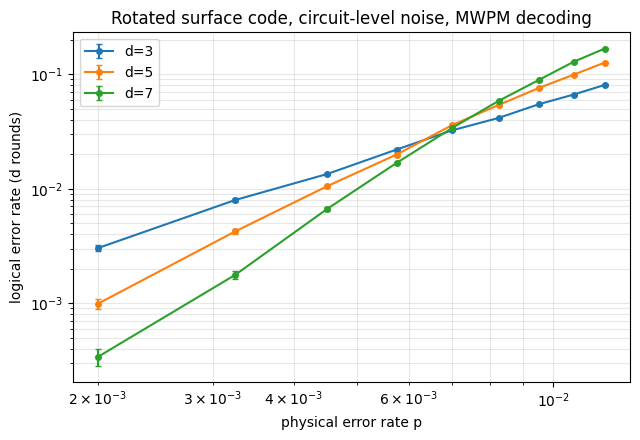

In [3]:
import argparse

import matplotlib.pyplot as plt
import numpy as np
import pymatching
import stim


def make_circuit(d: int, p: float, rounds: int | None = None) -> stim.Circuit:
    """Rotated surface code memory circuit with SI1000-style uniform noise."""
    return stim.Circuit.generated(
        "surface_code:rotated_memory_z",
        distance=d,
        rounds=rounds or d,
        after_clifford_depolarization=p,
        after_reset_flip_probability=p,
        before_measure_flip_probability=p,
        before_round_data_depolarization=p,
    )


def logical_error_rate(d: int, p: float, shots: int) -> tuple[float, float]:
    circuit = make_circuit(d, p)

    # Sample detection events and the true observable flips.
    sampler = circuit.compile_detector_sampler()
    detections, observables = sampler.sample(shots, separate_observables=True)

    # Build the matching graph from the detector error model and decode.
    dem = circuit.detector_error_model(decompose_errors=True)
    matcher = pymatching.Matching.from_detector_error_model(dem)
    predictions = matcher.decode_batch(detections)

    failures = int(np.sum(np.any(predictions != observables, axis=1)))
    rate = failures / shots
    stderr = np.sqrt(max(rate * (1 - rate), 1e-12) / shots)
    return rate, stderr


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--distances", type=int, nargs="+", default=[3, 5, 7])
    ap.add_argument("--shots", type=int, default=100_000)
    ap.add_argument("--pmin", type=float, default=0.002)
    ap.add_argument("--pmax", type=float, default=0.012)
    ap.add_argument("--npoints", type=int, default=9)
    ap.add_argument("--show-circuit", action="store_true")
    ap.add_argument("--out", default="stim_threshold.png")
    args = ap.parse_args()

    if args.show_circuit:
        print(make_circuit(3, 0.001))
        return

    ps = np.linspace(args.pmin, args.pmax, args.npoints)
    plt.figure(figsize=(6.5, 4.5))
    for d in args.distances:
        rates, errs = [], []
        for p in ps:
            r, e = logical_error_rate(d, p, args.shots)
            rates.append(r)
            errs.append(e)
            print(f"d={d} p={p:.4f}  logical error rate = {r:.5f} +/- {e:.5f}")
        plt.errorbar(ps, rates, yerr=errs, marker="o", ms=4, capsize=2, label=f"d={d}")

    plt.xlabel("physical error rate p")
    plt.ylabel("logical error rate (d rounds)")
    plt.xscale("log")
    plt.yscale("log")
    plt.title("Rotated surface code, circuit-level noise, MWPM decoding")
    plt.legend()
    plt.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    plt.savefig(args.out, dpi=150)
    print(f"saved {args.out}")


if __name__ == "__main__":
    import sys
    sys.argv = [
        "script.py",
        "--distances", "3", "5", "7",
        "--shots", "100000",
        "--pmin", "0.002",
        "--pmax", "0.012",
        "--npoints", "9"
    ]
    main()